# Week 02 — Attention Under the Hood
## Hand-Built Self-Attention with Attention-Map and Logit-Lens Probes

**Course:** Deep Learning & Neural Networks  
**Scenario:** Lumen Retail Analytics  
**Role:** Applied Research Intern  
**Interpretability Lead:** Marcus Oyelaran  

### Objective
Build and verify scaled dot-product self-attention and multi-head attention from scratch in PyTorch, train a tiny Transformer on a synthetic bracket-matching task, compare positional-encoding strategies, and investigate model behavior using attention-map and logit-lens probes.

### Experimental Plan
1. Configure the environment and reproducibility controls.
2. Generate a synthetic bracket-matching dataset in Python.
3. Implement sinusoidal and learned absolute positional encodings.
4. Implement scaled dot-product attention from scratch.
5. Implement multi-head attention from scratch.
6. Build a 4-layer, 4-head tiny Transformer.
7. Numerically verify the custom attention implementation.
8. Train the model and document convergence.
9. Compare positional-encoding behavior.
10. Generate labeled attention-map probes.
11. Apply a layer-by-layer logit-lens probe.
12. Perform a head-ablation intervention.
13. State what the evidence does and does not establish.

In [3]:
# ============================================================
# 1. Environment and Reproducibility
# ============================================================

import sys
import math
import random

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Use the best accelerator available locally.
if torch.backends.mps.is_available():
    device = torch.device("mps")       # Apple Silicon GPU
elif torch.cuda.is_available():
    device = torch.device("cuda")      # NVIDIA GPU / Colab
else:
    device = torch.device("cpu")

print("=" * 55)
print("Week 02 — Attention Under the Hood")
print("=" * 55)
print(f"Python version : {sys.version.split()[0]}")
print(f"PyTorch version: {torch.__version__}")
print(f"Random seed    : {SEED}")
print(f"Device         : {device}")
print("=" * 55)

Week 02 — Attention Under the Hood
Python version : 3.11.15
PyTorch version: 2.14.0
Random seed    : 42
Device         : mps


In [4]:
%pip install torch numpy matplotlib


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2. Synthetic Bracket-Matching Task

To create a controlled sequence-learning problem without an external dataset, this notebook generates balanced sequences using three bracket types: `()`, `[]`, and `{}`.

The generator maintains a stack of currently open brackets. At each step it either opens a new bracket or closes the most recently opened bracket. This guarantees properly nested sequences while still producing varied examples.

The resulting task requires the Transformer to use token identity, sequence position, and prior context to predict the next token. This makes bracket matching useful for examining attention patterns and intermediate residual-stream predictions.

In [5]:
# ============================================================
# 2. Synthetic Bracket-Matching Generator
# ============================================================

OPEN_TO_CLOSE = {
    "(": ")",
    "[": "]",
    "{": "}"
}

OPENERS = list(OPEN_TO_CLOSE.keys())


def generate_balanced_brackets(num_pairs=8, open_probability=0.60):
    """
    Generate one properly balanced and nested bracket sequence.

    Example:
        ['(', '[', ']', '{', '}', ')']

    A stack tracks unmatched opening brackets. New brackets can
    be opened while pairs remain; closing always removes the
    most recently opened bracket.
    """

    sequence = []
    stack = []
    opened = 0

    while opened < num_pairs or stack:

        # Open a new bracket if pairs remain and either:
        # 1. nothing is currently open, or
        # 2. the random draw favors opening another bracket.
        should_open = (
            opened < num_pairs
            and (not stack or random.random() < open_probability)
        )

        if should_open:
            opener = random.choice(OPENERS)
            sequence.append(opener)
            stack.append(opener)
            opened += 1

        else:
            opener = stack.pop()
            sequence.append(OPEN_TO_CLOSE[opener])

    return sequence


# Generate a few examples for inspection.
for i in range(5):
    example = generate_balanced_brackets(num_pairs=8)
    print(f"Example {i + 1}: {' '.join(example)}")

Example 1: { { ( ( ) ) [ ( { } { } ) ] } }
Example 2: { } [ { ( ) [ ( [ [ ] ] ) ] } ]
Example 3: ( [ ] ) { ( ) { { } } { { } } }
Example 4: ( ) ( ) ( [ ] [ { { } } { } ] )
Example 5: ( [ { } [ ] ] ( ) ( { } { } ) )


In [6]:
# ============================================================
# 3. Vocabulary and Tokenization
# ============================================================

# Special tokens plus the six bracket symbols.
TOKENS = ["<PAD>", "<BOS>", "(", ")", "[", "]", "{", "}"]

token_to_id = {token: idx for idx, token in enumerate(TOKENS)}
id_to_token = {idx: token for token, idx in token_to_id.items()}

PAD_ID = token_to_id["<PAD>"]
BOS_ID = token_to_id["<BOS>"]

VOCAB_SIZE = len(TOKENS)


def encode(sequence, add_bos=True):
    """Convert bracket symbols into integer token IDs."""
    ids = [token_to_id[token] for token in sequence]

    if add_bos:
        ids = [BOS_ID] + ids

    return ids


def decode(ids, skip_special=True):
    """Convert integer token IDs back into readable symbols."""
    tokens = [id_to_token[int(idx)] for idx in ids]

    if skip_special:
        tokens = [
            token for token in tokens
            if token not in {"<PAD>", "<BOS>"}
        ]

    return tokens


# Verify round-trip tokenization.
test_sequence = generate_balanced_brackets(num_pairs=4)
encoded = encode(test_sequence)
decoded = decode(encoded)

print("Vocabulary:")
print(token_to_id)

print("\nOriginal:")
print(" ".join(test_sequence))

print("\nEncoded:")
print(encoded)

print("\nDecoded:")
print(" ".join(decoded))

assert decoded == test_sequence

print("\nPASS: encode → decode round trip is correct.")

Vocabulary:
{'<PAD>': 0, '<BOS>': 1, '(': 2, ')': 3, '[': 4, ']': 5, '{': 6, '}': 7}

Original:
[ { [ { } ] } ]

Encoded:
[1, 4, 6, 4, 6, 7, 5, 7, 5]

Decoded:
[ { [ { } ] } ]

PASS: encode → decode round trip is correct.


In [7]:
# ============================================================
# 4. Next-Token Training Examples
# ============================================================

def make_training_example(num_pairs=8):
    """
    Generate one balanced bracket sequence and convert it into
    input/target tensors for causal next-token prediction.

    Input : <BOS> token_1 token_2 ... token_(n-1)
    Target: token_1 token_2 token_3 ... token_n
    """

    sequence = generate_balanced_brackets(num_pairs=num_pairs)
    token_ids = encode(sequence, add_bos=True)

    # Shift by one position for next-token prediction.
    x = torch.tensor(token_ids[:-1], dtype=torch.long)
    y = torch.tensor(token_ids[1:], dtype=torch.long)

    return x, y


# Inspect one example.
x, y = make_training_example(num_pairs=8)

print("INPUT IDs:")
print(x.tolist())

print("\nTARGET IDs:")
print(y.tolist())

print("\nINPUT TOKENS:")
print([id_to_token[int(idx)] for idx in x])

print("\nTARGET TOKENS:")
print([id_to_token[int(idx)] for idx in y])

print("\nTensor shapes:")
print("x:", tuple(x.shape))
print("y:", tuple(y.shape))

assert x.shape == y.shape
assert len(x) == 16

print("\nPASS: next-token input and target alignment is correct.")

INPUT IDs:
[1, 6, 6, 6, 2, 3, 4, 2, 3, 2, 3, 2, 3, 5, 7, 7]

TARGET IDs:
[6, 6, 6, 2, 3, 4, 2, 3, 2, 3, 2, 3, 5, 7, 7, 7]

INPUT TOKENS:
['<BOS>', '{', '{', '{', '(', ')', '[', '(', ')', '(', ')', '(', ')', ']', '}', '}']

TARGET TOKENS:
['{', '{', '{', '(', ')', '[', '(', ')', '(', ')', '(', ')', ']', '}', '}', '}']

Tensor shapes:
x: (16,)
y: (16,)

PASS: next-token input and target alignment is correct.


## 5. Positional Encodings

Self-attention alone does not encode token order, so positional information must be added to the token representations.

This experiment implements two positional-encoding strategies:

1. **Sinusoidal encoding** — deterministic sine and cosine functions represent position without learned position parameters.
2. **Learned absolute encoding** — each sequence position receives its own trainable embedding vector.

Both methods operate in the same `d_model` space as the token embeddings. Later experiments will compare their behavior within and beyond the training sequence length.

In [8]:
# ============================================================
# 5. Positional Encodings
# ============================================================

class SinusoidalPositionalEncoding(nn.Module):
    """
    Fixed sinusoidal positional encoding.

    Position information is generated mathematically rather
    than learned from the training data.
    """

    def __init__(self, d_model, max_len=128):
        super().__init__()

        position = torch.arange(
            max_len, dtype=torch.float32
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-math.log(10000.0) / d_model)
        )

        pe = torch.zeros(max_len, d_model)

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        # Positional values are fixed, not trainable parameters.
        self.register_buffer("pe", pe.unsqueeze(0))


    def forward(self, x):
        """
        x shape:
            (batch, sequence_length, d_model)
        """
        seq_len = x.size(1)

        return x + self.pe[:, :seq_len, :]


class LearnedAbsolutePositionalEncoding(nn.Module):
    """
    Learned absolute positional embeddings.

    Each position receives its own trainable d_model vector.
    """

    def __init__(self, d_model, max_len=128):
        super().__init__()

        self.position_embedding = nn.Embedding(
            max_len,
            d_model
        )


    def forward(self, x):
        """
        x shape:
            (batch, sequence_length, d_model)
        """
        seq_len = x.size(1)

        positions = torch.arange(
            seq_len,
            device=x.device
        )

        position_vectors = self.position_embedding(
            positions
        ).unsqueeze(0)

        return x + position_vectors


# ------------------------------------------------------------
# Shape verification
# ------------------------------------------------------------

D_MODEL = 64
TEST_LENGTH = 16

dummy_embeddings = torch.zeros(
    2,
    TEST_LENGTH,
    D_MODEL
)

sinusoidal_pe = SinusoidalPositionalEncoding(
    d_model=D_MODEL,
    max_len=128
)

learned_pe = LearnedAbsolutePositionalEncoding(
    d_model=D_MODEL,
    max_len=128
)

sin_output = sinusoidal_pe(dummy_embeddings)
learned_output = learned_pe(dummy_embeddings)

print("Input shape      :", tuple(dummy_embeddings.shape))
print("Sinusoidal shape :", tuple(sin_output.shape))
print("Learned shape    :", tuple(learned_output.shape))

assert sin_output.shape == dummy_embeddings.shape
assert learned_output.shape == dummy_embeddings.shape

print("\nPASS: both positional encodings preserve tensor shape.")

Input shape      : (2, 16, 64)
Sinusoidal shape : (2, 16, 64)
Learned shape    : (2, 16, 64)

PASS: both positional encodings preserve tensor shape.


## 6. Scaled Dot-Product Attention From Scratch

Scaled dot-product attention compares each query with every key, scales the resulting similarity scores by `1 / sqrt(d_k)`, applies an optional causal mask, normalizes the scores with softmax over the key dimension, and uses those attention weights to form a weighted combination of the value vectors.

This implementation is written directly with PyTorch tensor operations. It does not use `nn.MultiheadAttention` or a fused attention kernel.

\[
\mathrm{Attention}(Q,K,V)
=
\mathrm{softmax}\left(
\frac{QK^T}{\sqrt{d_k}} + M
\right)V
\]

For causal next-token prediction, the mask \(M\) prevents each query position from attending to future keys.

In [9]:
# ============================================================
# 6. Scaled Dot-Product Attention From Scratch
# ============================================================

def scaled_dot_product_attention(
    q,
    k,
    v,
    causal=True,
    return_weights=True
):
    """
    Compute scaled dot-product attention from scratch.

    Expected shapes:
        q: (batch, heads, query_length, d_head)
        k: (batch, heads, key_length,   d_head)
        v: (batch, heads, key_length,   d_head)

    Returns:
        output:
            (batch, heads, query_length, d_head)

        attention_weights:
            (batch, heads, query_length, key_length)
    """

    d_k = q.size(-1)

    # --------------------------------------------------------
    # 1. Query-key similarity
    # --------------------------------------------------------
    scores = torch.matmul(
        q,
        k.transpose(-2, -1)
    )

    # --------------------------------------------------------
    # 2. Scale by sqrt(d_k)
    # --------------------------------------------------------
    scores = scores / math.sqrt(d_k)

    # --------------------------------------------------------
    # 3. Apply causal mask
    # --------------------------------------------------------
    if causal:
        query_length = q.size(-2)
        key_length = k.size(-2)

        causal_mask = torch.triu(
            torch.ones(
                query_length,
                key_length,
                device=q.device,
                dtype=torch.bool
            ),
            diagonal=1
        )

        scores = scores.masked_fill(
            causal_mask,
            float("-inf")
        )

    # --------------------------------------------------------
    # 4. Normalize across keys
    # --------------------------------------------------------
    attention_weights = torch.softmax(
        scores,
        dim=-1
    )

    # --------------------------------------------------------
    # 5. Weighted sum of values
    # --------------------------------------------------------
    output = torch.matmul(
        attention_weights,
        v
    )

    if return_weights:
        return output, attention_weights

    return output


# ------------------------------------------------------------
# Basic functional test
# ------------------------------------------------------------

torch.manual_seed(SEED)

BATCH = 2
HEADS = 4
SEQ_LEN = 6
D_HEAD = 16

q = torch.randn(BATCH, HEADS, SEQ_LEN, D_HEAD)
k = torch.randn(BATCH, HEADS, SEQ_LEN, D_HEAD)
v = torch.randn(BATCH, HEADS, SEQ_LEN, D_HEAD)

attention_output, attention_weights = (
    scaled_dot_product_attention(
        q,
        k,
        v,
        causal=True
    )
)

print("Q shape               :", tuple(q.shape))
print("K shape               :", tuple(k.shape))
print("V shape               :", tuple(v.shape))
print("Attention output shape:", tuple(attention_output.shape))
print("Attention weight shape:", tuple(attention_weights.shape))

# Every query row should form a probability distribution.
row_sums = attention_weights.sum(dim=-1)

print(
    "\nMaximum row-sum error :",
    float((row_sums - 1.0).abs().max())
)

assert attention_output.shape == (
    BATCH,
    HEADS,
    SEQ_LEN,
    D_HEAD
)

assert attention_weights.shape == (
    BATCH,
    HEADS,
    SEQ_LEN,
    SEQ_LEN
)

assert torch.allclose(
    row_sums,
    torch.ones_like(row_sums),
    atol=1e-6
)

# Future positions must receive zero attention.
future_mask = torch.triu(
    torch.ones(
        SEQ_LEN,
        SEQ_LEN,
        dtype=torch.bool
    ),
    diagonal=1
)

future_weights = attention_weights[
    :,
    :,
    future_mask
]

assert torch.allclose(
    future_weights,
    torch.zeros_like(future_weights),
    atol=1e-7
)

print("PASS: attention rows sum to 1.")
print("PASS: causal mask assigns zero weight to future positions.")
print("PASS: scaled dot-product attention functional test complete.")

Q shape               : (2, 4, 6, 16)
K shape               : (2, 4, 6, 16)
V shape               : (2, 4, 6, 16)
Attention output shape: (2, 4, 6, 16)
Attention weight shape: (2, 4, 6, 6)

Maximum row-sum error : 1.1920928955078125e-07
PASS: attention rows sum to 1.
PASS: causal mask assigns zero weight to future positions.
PASS: scaled dot-product attention functional test complete.


## 7. Numerical Verification of Scaled Dot-Product Attention

A working implementation is not sufficient evidence that the attention calculation is correct. To verify the hand-built scaled dot-product attention, this section independently reconstructs the same computation using identical query, key, and value tensors and compares the resulting attention weights and outputs numerically.

The verification checks the maximum absolute error and uses a defined numerical tolerance to confirm agreement between the custom implementation and the reference calculation.

In [11]:
# ============================================================
# 7. Numerical Verification Against Reference Calculation
# ============================================================

# Reuse the exact same Q, K, and V tensors from our custom test.
d_k = q.size(-1)

# ------------------------------------------------------------
# Reference calculation written independently
# ------------------------------------------------------------

reference_scores = torch.matmul(
    q,
    k.transpose(-2, -1)
) / math.sqrt(d_k)

reference_mask = torch.triu(
    torch.ones(
        SEQ_LEN,
        SEQ_LEN,
        device=q.device,
        dtype=torch.bool
    ),
    diagonal=1
)

reference_scores = reference_scores.masked_fill(
    reference_mask,
    float("-inf")
)

reference_weights = torch.softmax(
    reference_scores,
    dim=-1
)

reference_output = torch.matmul(
    reference_weights,
    v
)

# ------------------------------------------------------------
# Compare custom implementation with reference
# ------------------------------------------------------------

custom_output, custom_weights = scaled_dot_product_attention(
    q,
    k,
    v,
    causal=True
)

output_max_error = (
    custom_output - reference_output
).abs().max().item()

weight_max_error = (
    custom_weights - reference_weights
).abs().max().item()

print("Custom output shape   :", tuple(custom_output.shape))
print("Reference output shape:", tuple(reference_output.shape))

print("\nMaximum output error  :", output_max_error)
print("Maximum weight error  :", weight_max_error)

assert torch.allclose(
    custom_output,
    reference_output,
    atol=1e-6,
    rtol=1e-5
)

assert torch.allclose(
    custom_weights,
    reference_weights,
    atol=1e-6,
    rtol=1e-5
)

print("\nPASS: custom attention matches the reference calculation.")
print("PASS: numerical verification is within tolerance.")

Custom output shape   : (2, 4, 6, 16)
Reference output shape: (2, 4, 6, 16)

Maximum output error  : 0.0
Maximum weight error  : 0.0

PASS: custom attention matches the reference calculation.
PASS: numerical verification is within tolerance.


## 8. Multi-Head Attention From Scratch

Multi-head attention projects the residual-stream representation into separate query, key, and value representations, then divides those representations across multiple attention heads.

For this model, `d_model = 64` and `num_heads = 4`, giving each head:

\[
d_{head} = \frac{64}{4} = 16
\]

Each head independently applies the hand-built scaled dot-product attention function. The resulting head outputs are then concatenated and passed through an output projection \(W_O\), returning the representation to the original `d_model` width.

The implementation below uses explicit linear projections, reshaping, transposition, concatenation, and output projection. It does not use `nn.MultiheadAttention` or fused attention kernels.

In [29]:
# ============================================================
# 8. Multi-Head Attention From Scratch
# ============================================================

class MultiHeadSelfAttention(nn.Module):
    """
    Multi-head causal self-attention built from scratch.

    No nn.MultiheadAttention or fused attention kernels are used.
    """

    def __init__(self, d_model=64, num_heads=4):
        super().__init__()

        assert d_model % num_heads == 0, (
            "d_model must be divisible by num_heads"
        )

        self.d_model = d_model
        self.num_heads = num_heads
        self.d_head = d_model // num_heads

        # Learned Q, K, and V projections.
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)

        # Output projection W_O.
        self.W_o = nn.Linear(d_model, d_model)


    def split_heads(self, x):
        """
        Convert:
            (batch, seq_len, d_model)

        into:
            (batch, num_heads, seq_len, d_head)
        """

        batch_size, seq_len, _ = x.shape

        x = x.reshape(
            batch_size,
            seq_len,
            self.num_heads,
            self.d_head
        )

        return x.transpose(1, 2)


    def combine_heads(self, x):
        """
        Convert:
            (batch, num_heads, seq_len, d_head)

        back into:
            (batch, seq_len, d_model)
        """

        batch_size, _, seq_len, _ = x.shape

        # transpose() changes the memory layout, so contiguous()
        # is called before reshaping the heads back together.
        x = x.transpose(1, 2).contiguous()

        return x.reshape(
            batch_size,
            seq_len,
            self.d_model
        )


    def forward(
        self,
        x,
        causal=True,
        return_weights=False,
        ablate_head=None
    ):
        # Project residual-stream input into Q, K, and V.
        q = self.W_q(x)
        k = self.W_k(x)
        v = self.W_v(x)

        # Split d_model into parallel attention heads.
        q = self.split_heads(q)
        k = self.split_heads(k)
        v = self.split_heads(v)

        # Apply our hand-built attention function.
        head_output, attention_weights = (
            scaled_dot_product_attention(
                q,
                k,
                v,
                causal=causal,
                return_weights=True
            )
        )
        # Optional causal intervention: zero one attention head
        # before the heads are recombined and projected through W_O.
        if ablate_head is not None:
            if not 0 <= ablate_head < self.num_heads:
                raise ValueError(
                    f"ablate_head must be between 0 and "
                    f"{self.num_heads - 1}"
            )
            head_output = head_output.clone()
            head_output[:, ablate_head, :, :] = 0.0
            
        # Concatenate the head outputs.
        combined = self.combine_heads(head_output)

        # Mix head information and write back to d_model.
        output = self.W_o(combined)

        if return_weights:
            return output, attention_weights

        return output


# ------------------------------------------------------------
# Shape and behavior verification
# ------------------------------------------------------------

torch.manual_seed(SEED)

BATCH = 2
SEQ_LEN = 16
D_MODEL = 64
NUM_HEADS = 4

test_residual = torch.randn(
    BATCH,
    SEQ_LEN,
    D_MODEL
)

mha = MultiHeadSelfAttention(
    d_model=D_MODEL,
    num_heads=NUM_HEADS
)

mha_output, mha_weights = mha(
    test_residual,
    causal=True,
    return_weights=True
)

print("Residual input shape :", tuple(test_residual.shape))
print("Number of heads      :", NUM_HEADS)
print("d_head               :", mha.d_head)
print("Attention weights    :", tuple(mha_weights.shape))
print("Final output         :", tuple(mha_output.shape))

assert mha.d_head == 16

assert mha_weights.shape == (
    BATCH,
    NUM_HEADS,
    SEQ_LEN,
    SEQ_LEN
)

assert mha_output.shape == (
    BATCH,
    SEQ_LEN,
    D_MODEL
)

print("\nPASS: d_head = d_model / num_heads = 16.")
print("PASS: attention weights have (batch, heads, seq, seq) shape.")
print("PASS: output is re-projected to the original d_model width.")

Residual input shape : (2, 16, 64)
Number of heads      : 4
d_head               : 16
Attention weights    : (2, 4, 16, 16)
Final output         : (2, 16, 64)

PASS: d_head = d_model / num_heads = 16.
PASS: attention weights have (batch, heads, seq, seq) shape.
PASS: output is re-projected to the original d_model width.


## 9. Pre-Norm Transformer Block and Residual Stream

The multi-head attention mechanism is now incorporated into a complete Transformer block. Each block contains two sublayers: multi-head self-attention and a feed-forward neural network (MLP).

This implementation uses a **pre-norm architecture**, where LayerNorm is applied before each sublayer:

\[
x' = x + \text{Attention}(\text{LayerNorm}(x))
\]

\[
x'' = x' + \text{MLP}(\text{LayerNorm}(x'))
\]

The residual stream remains `d_model = 64` dimensions wide throughout the block. Attention and the MLP therefore contribute updates to the same running representation without changing its shape.

The block can also return its attention weights, allowing individual layers and heads to be inspected later with attention-map probes.

In [30]:
# ============================================================
# 9. Pre-Norm Transformer Block and Residual Stream
# ============================================================

class TransformerBlock(nn.Module):
    """
    Pre-norm Transformer block built around our
    hand-written multi-head self-attention module.
    """

    def __init__(
        self,
        d_model=64,
        num_heads=4,
        d_ff=128
    ):
        super().__init__()

        # Pre-attention normalization.
        self.ln1 = nn.LayerNorm(d_model)

        # Our hand-built multi-head attention.
        self.attention = MultiHeadSelfAttention(
            d_model=d_model,
            num_heads=num_heads
        )

        # Pre-MLP normalization.
        self.ln2 = nn.LayerNorm(d_model)

        # Position-wise feed-forward network.
        self.mlp = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Linear(d_ff, d_model)
        )


    def forward(
        self,
        x,
        causal=True,
        return_weights=False,
        ablate_head=None
    ):
        # ----------------------------------------------------
        # Attention residual update
        #
        # x <- x + Attention(LayerNorm(x))
        # ----------------------------------------------------
        normalized_x = self.ln1(x)

        attention_output, attention_weights = self.attention(
            normalized_x,
            causal=causal,
            return_weights=True,
            ablate_head=ablate_head
        )

        x = x + attention_output

        # ----------------------------------------------------
        # MLP residual update
        #
        # x <- x + MLP(LayerNorm(x))
        # ----------------------------------------------------
        normalized_x = self.ln2(x)

        mlp_output = self.mlp(normalized_x)

        x = x + mlp_output

        if return_weights:
            return x, attention_weights

        return x


# ------------------------------------------------------------
# Verify the Transformer block
# ------------------------------------------------------------

torch.manual_seed(SEED)

test_block = TransformerBlock(
    d_model=64,
    num_heads=4,
    d_ff=128
)

block_input = torch.randn(
    2,
    16,
    64
)

block_output, block_weights = test_block(
    block_input,
    causal=True,
    return_weights=True
)

print("Block input shape     :", tuple(block_input.shape))
print("Block output shape    :", tuple(block_output.shape))
print("Attention weight shape:", tuple(block_weights.shape))

assert block_output.shape == block_input.shape

assert block_weights.shape == (
    2,
    4,
    16,
    16
)

print("\nPASS: residual-stream width is preserved.")
print("PASS: Transformer block returns per-head attention weights.")
print("PASS: pre-norm attention and MLP residual updates execute correctly.")

Block input shape     : (2, 16, 64)
Block output shape    : (2, 16, 64)
Attention weight shape: (2, 4, 16, 16)

PASS: residual-stream width is preserved.
PASS: Transformer block returns per-head attention weights.
PASS: pre-norm attention and MLP residual updates execute correctly.


## 10. Four-Layer Toy Transformer

The verified Transformer block is now stacked into a four-layer causal Transformer for the synthetic bracket-matching task.

The model consists of a token embedding layer, a selectable positional-encoding strategy, four pre-norm Transformer blocks, a final LayerNorm, and an output projection over the bracket vocabulary.

During the forward pass, the model stores two forms of internal evidence:

- **Attention weights** from every layer and every head for later attention-map visualization.
- **Residual-stream activations** after each Transformer block for the layer-by-layer logit-lens probe.

Capturing both is important because an attention pattern shows where a head reads information, while the residual stream shows when information becomes decodable by the model's output head. Neither probe alone establishes causal responsibility.

In [32]:
# ============================================================
# 10. Four-Layer Toy Transformer
# ============================================================

class TinyTransformer(nn.Module):
    """
    Four-layer, four-head causal Transformer for the
    synthetic bracket-matching next-token task.
    """

    def __init__(
        self,
        vocab_size,
        max_seq_len=64,
        d_model=64,
        num_heads=4,
        num_layers=4,
        d_ff=128,
        positional_encoding="sinusoidal"
    ):
        super().__init__()

        self.d_model = d_model
        self.num_layers = num_layers
        self.positional_encoding_type = positional_encoding

        # Token representation.
        self.token_embedding = nn.Embedding(
            vocab_size,
            d_model
        )

        # Choose one of our two positional encodings.
        if positional_encoding == "sinusoidal":
            self.position = SinusoidalPositionalEncoding(
                d_model=d_model,
                max_len=max_seq_len
            )

        elif positional_encoding == "learned":
            self.position = LearnedPositionalEncoding(
                d_model=d_model,
                max_len=max_seq_len
            )

        else:
            raise ValueError(
                "positional_encoding must be "
                "'sinusoidal' or 'learned'"
            )

        # Stack four of our hand-built Transformer blocks.
        self.blocks = nn.ModuleList([
            TransformerBlock(
                d_model=d_model,
                num_heads=num_heads,
                d_ff=d_ff
            )
            for _ in range(num_layers)
        ])

        # Final normalization before vocabulary decoding.
        self.final_ln = nn.LayerNorm(d_model)

        # Output / unembedding head.
        self.output_head = nn.Linear(
            d_model,
            vocab_size,
            bias=False
        )


    def forward(
        self,
        token_ids,
        return_probes=False,
        ablate_layer=None,
        ablate_head=None
    ):
        # ----------------------------------------------------
        # Token + positional representation
        # ----------------------------------------------------

        x = self.token_embedding(token_ids)

        x = self.position(x)

        # Containers for interpretability evidence.
        attention_maps = []
        residual_streams = []

        # ----------------------------------------------------
        # Transformer stack
        # ----------------------------------------------------

        for layer_idx, block in enumerate(self.blocks):
            # Only ablate the requested head in the requested layer.
            head_to_ablate = (
                ablate_head
                if ablate_layer == layer_idx
                else None
            )

            x, attention_weights = block(
                x,
                causal=True,
                return_weights=True,
                ablate_head=head_to_ablate
            )

            # Save evidence before moving to next layer.
            attention_maps.append(attention_weights)
            residual_streams.append(x)

        # ----------------------------------------------------
        # Final vocabulary prediction
        # ----------------------------------------------------

        normalized_x = self.final_ln(x)

        logits = self.output_head(normalized_x)

        if return_probes:
            return (
                logits,
                attention_maps,
                residual_streams
            )

        return logits


# ------------------------------------------------------------
# Verify complete architecture
# ------------------------------------------------------------

torch.manual_seed(SEED)

VOCAB_SIZE = len(token_to_id)

model = TinyTransformer(
    vocab_size=VOCAB_SIZE,
    max_seq_len=64,
    d_model=64,
    num_heads=4,
    num_layers=4,
    d_ff=128,
    positional_encoding="sinusoidal"
)

test_tokens = torch.randint(
    0,
    VOCAB_SIZE,
    (2, 16)
)

logits, attention_maps, residual_streams = model(
    test_tokens,
    return_probes=True
)

print("Input token shape       :", tuple(test_tokens.shape))
print("Final logits shape      :", tuple(logits.shape))
print("Transformer layers      :", len(residual_streams))
print("Attention-map sets      :", len(attention_maps))

for layer_index in range(4):
    print(
        f"Layer {layer_index + 1}: "
        f"residual {tuple(residual_streams[layer_index].shape)}, "
        f"attention {tuple(attention_maps[layer_index].shape)}"
    )


# ------------------------------------------------------------
# Assertions
# ------------------------------------------------------------

assert logits.shape == (
    2,
    16,
    VOCAB_SIZE
)

assert len(residual_streams) == 4
assert len(attention_maps) == 4

for residual in residual_streams:
    assert residual.shape == (
        2,
        16,
        64
    )

for weights in attention_maps:
    assert weights.shape == (
        2,
        4,
        16,
        16
    )

print("\nPASS: four Transformer layers execute successfully.")
print("PASS: all layer residual streams are captured.")
print("PASS: all layer/head attention maps are captured.")
print("PASS: output logits cover the complete vocabulary.")

Input token shape       : (2, 16)
Final logits shape      : (2, 16, 8)
Transformer layers      : 4
Attention-map sets      : 4
Layer 1: residual (2, 16, 64), attention (2, 4, 16, 16)
Layer 2: residual (2, 16, 64), attention (2, 4, 16, 16)
Layer 3: residual (2, 16, 64), attention (2, 4, 16, 16)
Layer 4: residual (2, 16, 64), attention (2, 4, 16, 16)

PASS: four Transformer layers execute successfully.
PASS: all layer residual streams are captured.
PASS: all layer/head attention maps are captured.
PASS: output logits cover the complete vocabulary.


## 11. Training Data and Mini-Batch Generation

The model is trained as a causal next-token predictor on synthetically generated balanced bracket sequences. Each training example begins with a BOS token followed by a sequence containing matched `()`, `[]`, and `{}` bracket pairs.

For causal language modeling, the input sequence is shifted by one position relative to the target sequence. At each position, the model therefore predicts the next bracket token using only the current token and preceding context.

Training sequences are generated dynamically rather than loaded from an external dataset. This keeps the experiment reproducible while satisfying the requirement to create the synthetic sequence task directly in Python.

In [19]:
# ============================================================
# 11. Training Data and Mini-Batch Generation
# ============================================================

def make_training_example(num_pairs=8):
    """
    Generate one balanced bracket sequence and convert it
    into causal next-token input and target tensors.
    """

    sequence = generate_balanced_brackets(
        num_pairs=num_pairs
    )

    encoded = encode(sequence)

    # encoded already contains BOS from our earlier encoder.
    x = torch.tensor(
        encoded[:-1],
        dtype=torch.long
    )

    y = torch.tensor(
        encoded[1:],
        dtype=torch.long
    )

    return x, y


def make_batch(
    batch_size=32,
    num_pairs=8,
    device=device
):
    """
    Generate a mini-batch of equal-length synthetic examples.
    """

    inputs = []
    targets = []

    for _ in range(batch_size):
        x, y = make_training_example(
            num_pairs=num_pairs
        )

        inputs.append(x)
        targets.append(y)

    x_batch = torch.stack(inputs).to(device)
    y_batch = torch.stack(targets).to(device)

    return x_batch, y_batch


# ------------------------------------------------------------
# Verify batching
# ------------------------------------------------------------

train_x, train_y = make_batch(
    batch_size=32,
    num_pairs=8
)

print("Training input shape :", tuple(train_x.shape))
print("Training target shape:", tuple(train_y.shape))
print("Device               :", train_x.device)

print("\nFirst input IDs:")
print(train_x[0].detach().cpu().tolist())

print("\nFirst target IDs:")
print(train_y[0].detach().cpu().tolist())

assert train_x.shape == train_y.shape
assert train_x.shape[0] == 32
assert train_x.dtype == torch.long
assert train_y.dtype == torch.long

print("\nPASS: batch inputs and targets have matching shapes.")
print("PASS: batch contains 32 synthetic training examples.")
print("PASS: token IDs use integer tensors required by nn.Embedding.")

Training input shape : (32, 16)
Training target shape: (32, 16)
Device               : mps:0

First input IDs:
[1, 6, 6, 7, 2, 3, 6, 2, 2, 6, 7, 4, 5, 3, 3, 7]

First target IDs:
[6, 6, 7, 2, 3, 6, 2, 2, 6, 7, 4, 5, 3, 3, 7, 7]

PASS: batch inputs and targets have matching shapes.
PASS: batch contains 32 synthetic training examples.
PASS: token IDs use integer tensors required by nn.Embedding.


## 12. Model Training and Convergence

The four-layer Transformer is trained on dynamically generated balanced-bracket sequences using causal next-token prediction. Cross-entropy loss measures the difference between the predicted vocabulary distribution and the correct next token at every sequence position.

The AdamW optimizer updates all trainable parameters through backpropagation. Training loss and next-token accuracy are recorded throughout the run to provide direct evidence of convergence rather than relying only on a final performance value.

The sinusoidal positional-encoding model is used as the primary experimental model. Training uses newly generated synthetic batches at each step, reducing dependence on memorization of a fixed dataset.

In [37]:
# ============================================================
# 12. Model Training and Convergence
# ============================================================

torch.manual_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

# Re-create the model so training begins from a controlled
# initialization.
model = TinyTransformer(
    vocab_size=len(token_to_id),
    max_seq_len=64,
    d_model=64,
    num_heads=4,
    num_layers=4,
    d_ff=128,
    positional_encoding="sinusoidal"
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=0.01
)

NUM_STEPS = 500
BATCH_SIZE = 32
NUM_PAIRS = 8

loss_history = []
accuracy_history = []

model.train()

for step in range(1, NUM_STEPS + 1):

    # Generate a fresh synthetic batch.
    x_batch, y_batch = make_batch(
        batch_size=BATCH_SIZE,
        num_pairs=NUM_PAIRS,
        device=device
    )

    # Forward pass.
    logits = model(x_batch)

    # Cross-entropy expects:
    # predictions -> (N, vocab_size)
    # targets     -> (N,)
    loss = F.cross_entropy(
        logits.reshape(-1, logits.size(-1)),
        y_batch.reshape(-1)
    )

    # Backpropagation.
    optimizer.zero_grad()
    loss.backward()

    # Gradient clipping adds stability.
    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=1.0
    )

    optimizer.step()

    # --------------------------------------------------------
    # Measure next-token accuracy
    # --------------------------------------------------------

    with torch.no_grad():

        predictions = logits.argmax(dim=-1)

        accuracy = (
            predictions == y_batch
        ).float().mean().item()

    loss_history.append(loss.item())
    accuracy_history.append(accuracy)

    # Report progress every 50 steps.
    if step == 1 or step % 50 == 0:

        print(
            f"Step {step:>3}/{NUM_STEPS} | "
            f"Loss: {loss.item():.4f} | "
            f"Accuracy: {accuracy:.4f}"
        )


print("\nTraining complete.")

print(
    f"Initial loss : {loss_history[0]:.4f}"
)

print(
    f"Final loss   : {loss_history[-1]:.4f}"
)

print(
    f"Final accuracy: {accuracy_history[-1]:.4f}"
)

assert loss_history[-1] < loss_history[0]

print("\nPASS: training loss decreased from initialization.")

Step   1/500 | Loss: 2.3958 | Accuracy: 0.0469
Step  50/500 | Loss: 1.3580 | Accuracy: 0.4180
Step 100/500 | Loss: 1.2883 | Accuracy: 0.4434
Step 150/500 | Loss: 1.1794 | Accuracy: 0.4980
Step 200/500 | Loss: 1.1610 | Accuracy: 0.4805
Step 250/500 | Loss: 1.1447 | Accuracy: 0.4961
Step 300/500 | Loss: 1.1049 | Accuracy: 0.5234
Step 350/500 | Loss: 1.0887 | Accuracy: 0.4980
Step 400/500 | Loss: 1.0763 | Accuracy: 0.5293
Step 450/500 | Loss: 1.0339 | Accuracy: 0.5215
Step 500/500 | Loss: 1.0483 | Accuracy: 0.5156

Training complete.
Initial loss : 2.3958
Final loss   : 1.0483
Final accuracy: 0.5156

PASS: training loss decreased from initialization.


## 13. Extended Training and Convergence Analysis

The initial 500-step training run demonstrated clear learning, with loss decreasing substantially from initialization. Because performance was still improving at step 500, training is continued from the existing model rather than restarting it.

Loss and next-token accuracy are tracked across the complete training history. The resulting learning curves provide visual evidence of whether optimization is approaching a stable region before interpretability probes are applied.

Step  600 | Loss: 0.9696 | Accuracy: 0.5625
Step  700 | Loss: 0.9331 | Accuracy: 0.5332
Step  800 | Loss: 0.9255 | Accuracy: 0.5410
Step  900 | Loss: 0.9746 | Accuracy: 0.5488
Step 1000 | Loss: 0.9747 | Accuracy: 0.5566
Step 1100 | Loss: 0.9503 | Accuracy: 0.5449
Step 1200 | Loss: 0.9315 | Accuracy: 0.5566
Step 1300 | Loss: 0.9380 | Accuracy: 0.5527
Step 1400 | Loss: 0.9423 | Accuracy: 0.5391
Step 1500 | Loss: 0.9713 | Accuracy: 0.5488


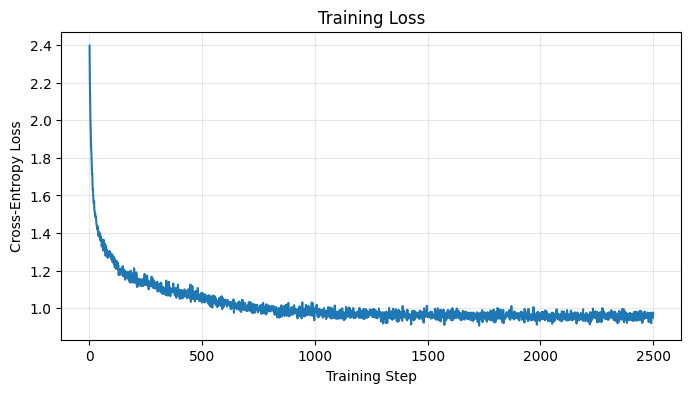

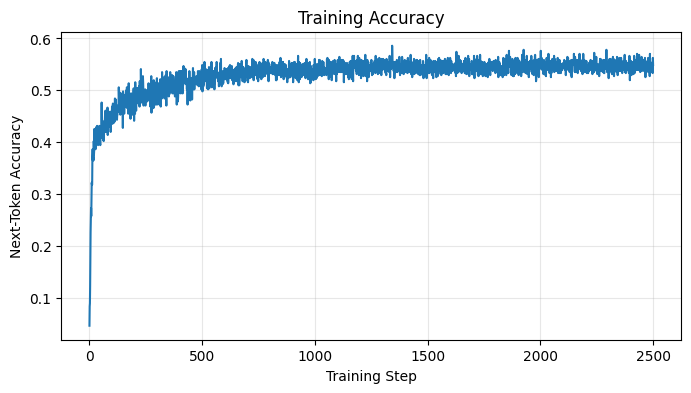


Training summary
----------------------------------------
Total steps       : 2500
Initial loss      : 2.3958
Final loss        : 0.9713
Initial accuracy  : 0.0469
Final accuracy    : 0.5488

PASS: extended training completed.


In [39]:
# ============================================================
# 13. Continue Training and Analyze Convergence
# ============================================================

ADDITIONAL_STEPS = 1000

model.train()

for step in range(1, ADDITIONAL_STEPS + 1):

    x_batch, y_batch = make_batch(
        batch_size=BATCH_SIZE,
        num_pairs=NUM_PAIRS,
        device=device
    )

    logits = model(x_batch)

    loss = F.cross_entropy(
        logits.reshape(-1, logits.size(-1)),
        y_batch.reshape(-1)
    )

    optimizer.zero_grad()
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=1.0
    )

    optimizer.step()

    with torch.no_grad():
        predictions = logits.argmax(dim=-1)

        accuracy = (
            predictions == y_batch
        ).float().mean().item()

    loss_history.append(loss.item())
    accuracy_history.append(accuracy)

    if step % 100 == 0:
        total_step = NUM_STEPS + step

        print(
            f"Step {total_step:>4} | "
            f"Loss: {loss.item():.4f} | "
            f"Accuracy: {accuracy:.4f}"
        )


# ------------------------------------------------------------
# Plot complete training history
# ------------------------------------------------------------

import matplotlib.pyplot as plt

steps = range(1, len(loss_history) + 1)

plt.figure(figsize=(8, 4))
plt.plot(steps, loss_history)
plt.xlabel("Training Step")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training Loss")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(steps, accuracy_history)
plt.xlabel("Training Step")
plt.ylabel("Next-Token Accuracy")
plt.title("Training Accuracy")
plt.grid(alpha=0.3)
plt.show()


print("\nTraining summary")
print("-" * 40)
print(f"Total steps       : {len(loss_history)}")
print(f"Initial loss      : {loss_history[0]:.4f}")
print(f"Final loss        : {loss_history[-1]:.4f}")
print(f"Initial accuracy  : {accuracy_history[0]:.4f}")
print(f"Final accuracy    : {accuracy_history[-1]:.4f}")

print("\nPASS: extended training completed.")

## 14. Held-Out Evaluation

To distinguish training convergence from memorization of individual generated batches, the trained model is evaluated on newly generated bracket sequences that were not used for parameter updates.

The model is placed in evaluation mode and tested across multiple fresh batches. Mean cross-entropy loss and next-token accuracy are reported. Similar training and held-out performance would indicate that the learned behavior generalizes across sequences drawn from the same synthetic data-generating process.

In [40]:
# ============================================================
# 14. Held-Out Evaluation
# ============================================================

model.eval()

EVAL_BATCHES = 20
EVAL_BATCH_SIZE = 64

eval_losses = []
eval_accuracies = []

with torch.no_grad():

    for _ in range(EVAL_BATCHES):

        x_eval, y_eval = make_batch(
            batch_size=EVAL_BATCH_SIZE,
            num_pairs=NUM_PAIRS,
            device=device
        )

        logits = model(x_eval)

        loss = F.cross_entropy(
            logits.reshape(-1, logits.size(-1)),
            y_eval.reshape(-1)
        )

        predictions = logits.argmax(dim=-1)

        accuracy = (
            predictions == y_eval
        ).float().mean().item()

        eval_losses.append(loss.item())
        eval_accuracies.append(accuracy)


mean_eval_loss = sum(eval_losses) / len(eval_losses)
mean_eval_accuracy = sum(eval_accuracies) / len(eval_accuracies)

print("Held-Out Evaluation")
print("=" * 45)
print(f"Evaluation batches : {EVAL_BATCHES}")
print(f"Sequences tested   : {EVAL_BATCHES * EVAL_BATCH_SIZE}")
print(f"Mean loss          : {mean_eval_loss:.4f}")
print(f"Mean accuracy      : {mean_eval_accuracy:.4f}")
print(f"Min accuracy       : {min(eval_accuracies):.4f}")
print(f"Max accuracy       : {max(eval_accuracies):.4f}")
print("=" * 45)

assert 0.0 <= mean_eval_accuracy <= 1.0
assert mean_eval_loss > 0

print("\nPASS: held-out evaluation completed successfully.")

Held-Out Evaluation
Evaluation batches : 20
Sequences tested   : 1280
Mean loss          : 0.9564
Mean accuracy      : 0.5458
Min accuracy       : 0.5264
Max accuracy       : 0.5635

PASS: held-out evaluation completed successfully.


## 15. Interpretability Probe 1 — Labeled Attention Maps

Attention weights are inspected for a hand-picked balanced-bracket sequence after training. Each heatmap represents one attention head within one Transformer layer. Rows correspond to query-token positions and columns correspond to key-token positions.

The purpose of this probe is to identify visible attention patterns such as self-attention, previous-token attention, beginning-of-sequence concentration, or possible relationships between bracket positions.

These visualizations provide descriptive evidence about where each head places attention. They do not, by themselves, establish that a head causally implements bracket matching or is necessary for the model's prediction.

Probe sequence:
<BOS> ( [ { } ] )

Number of layers captured: 4
Layer 1 attention shape: (1, 4, 7, 7)
Layer 2 attention shape: (1, 4, 7, 7)
Layer 3 attention shape: (1, 4, 7, 7)
Layer 4 attention shape: (1, 4, 7, 7)


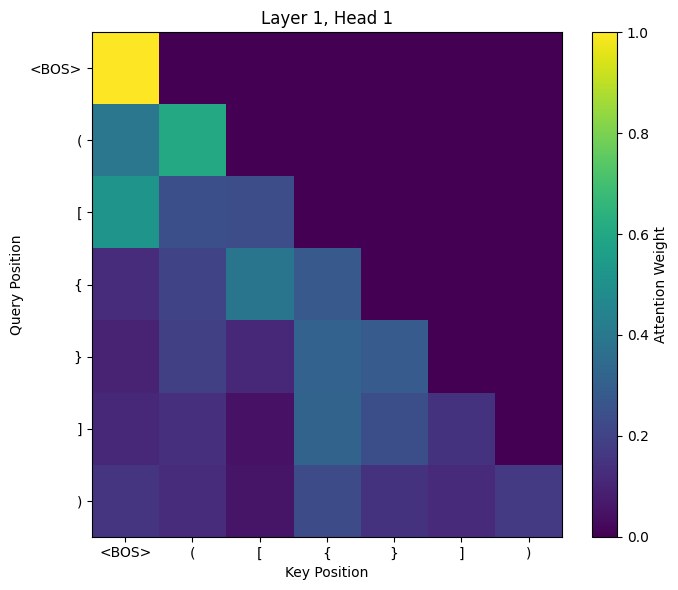

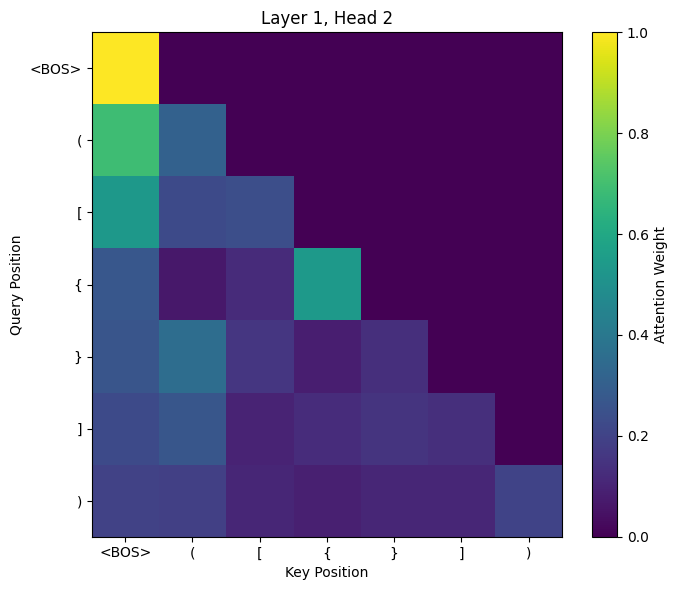

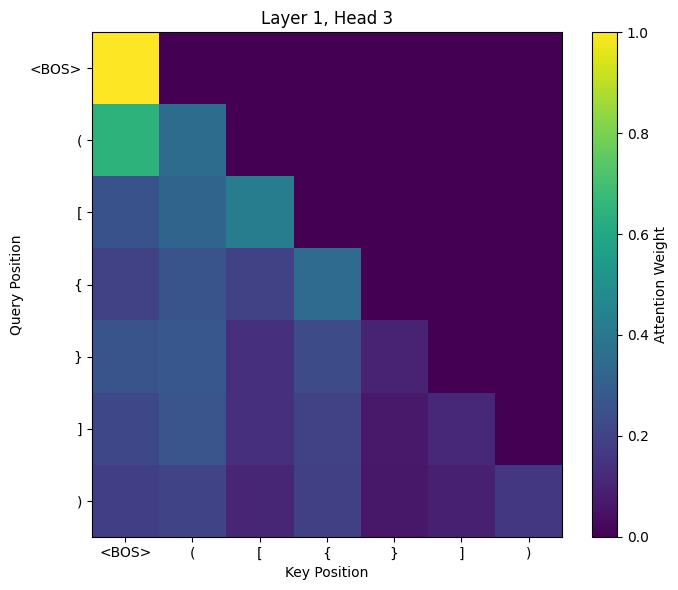

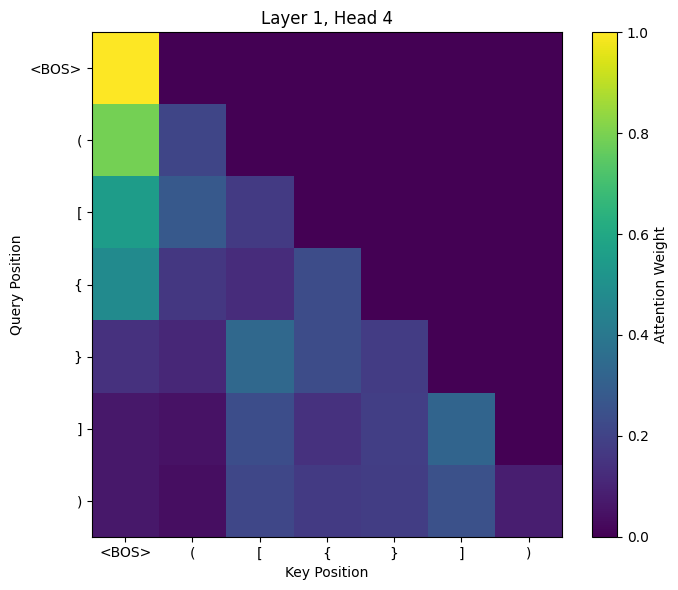

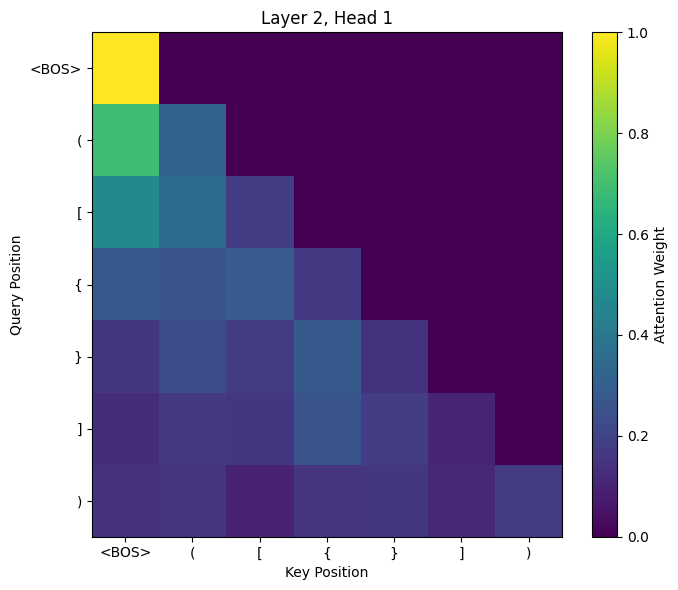

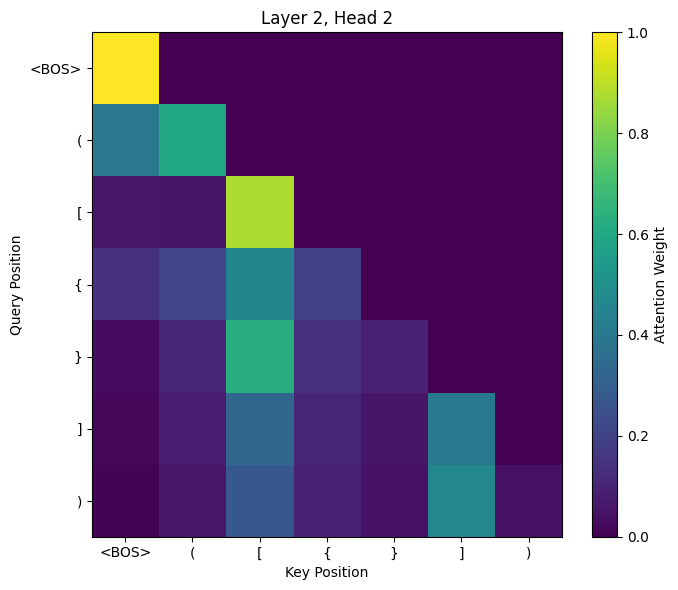

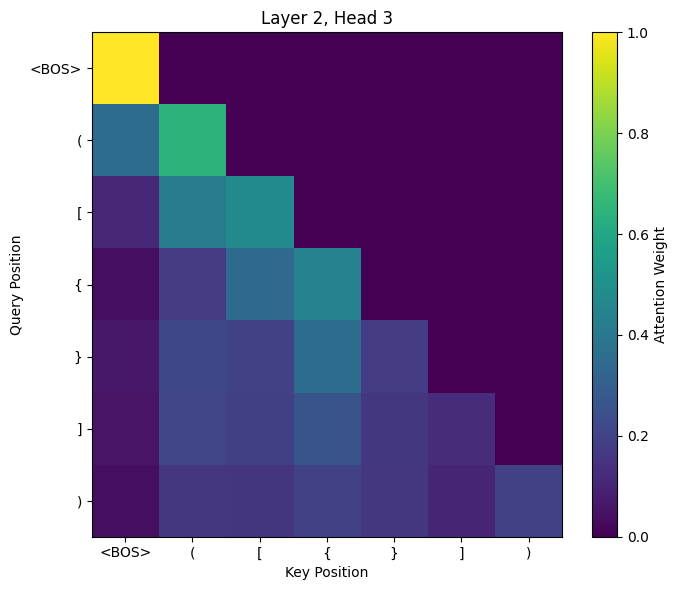

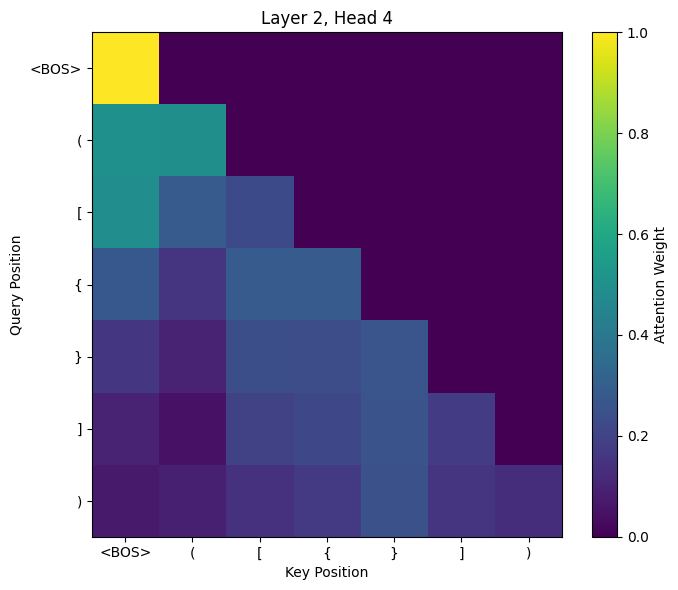

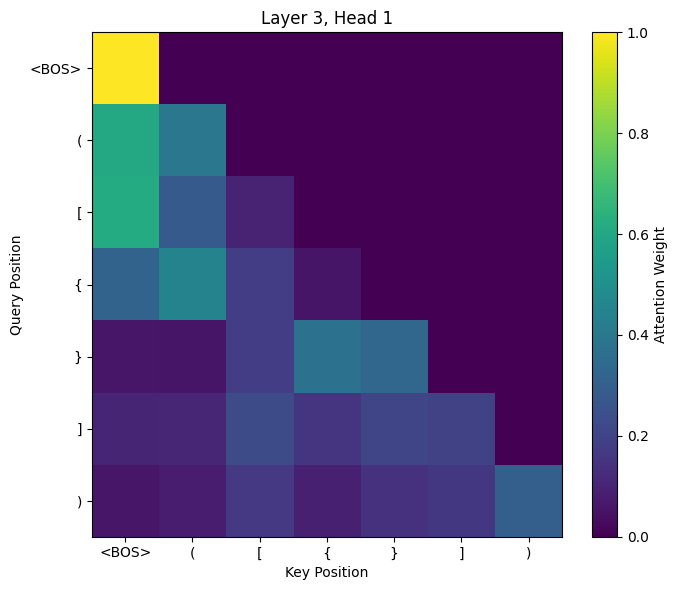

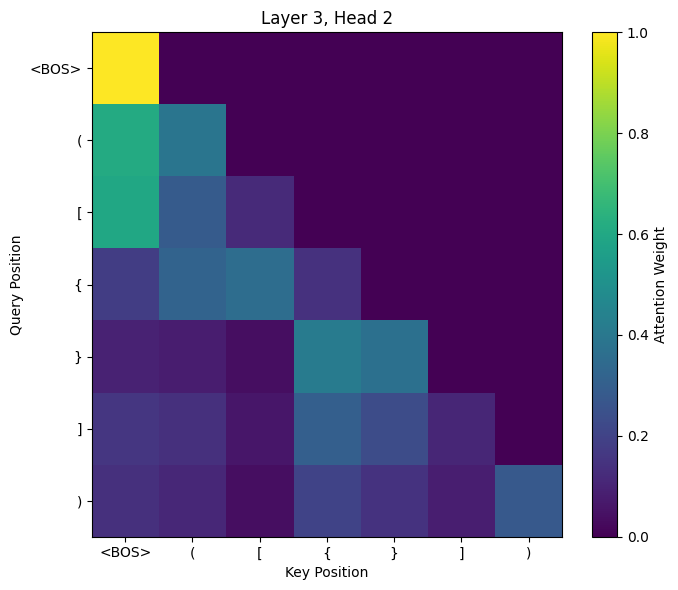

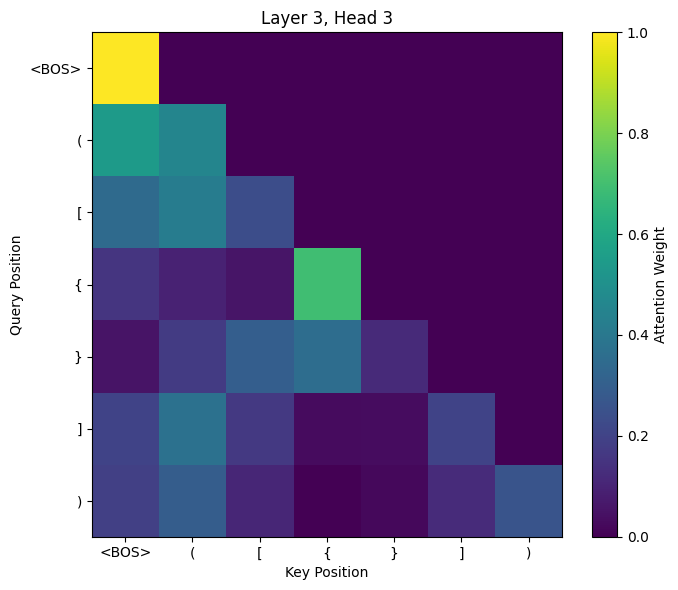

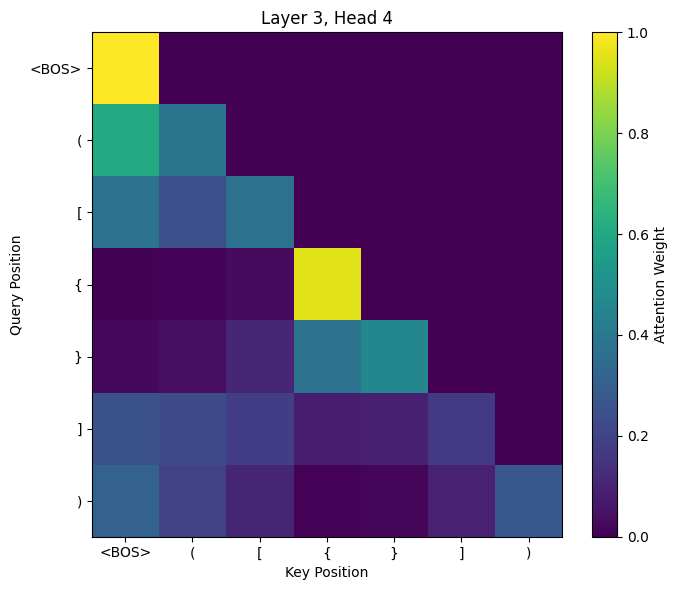

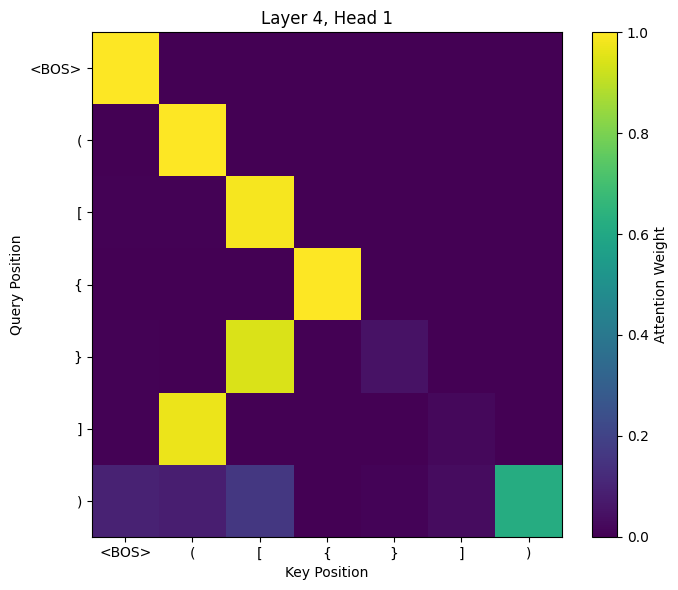

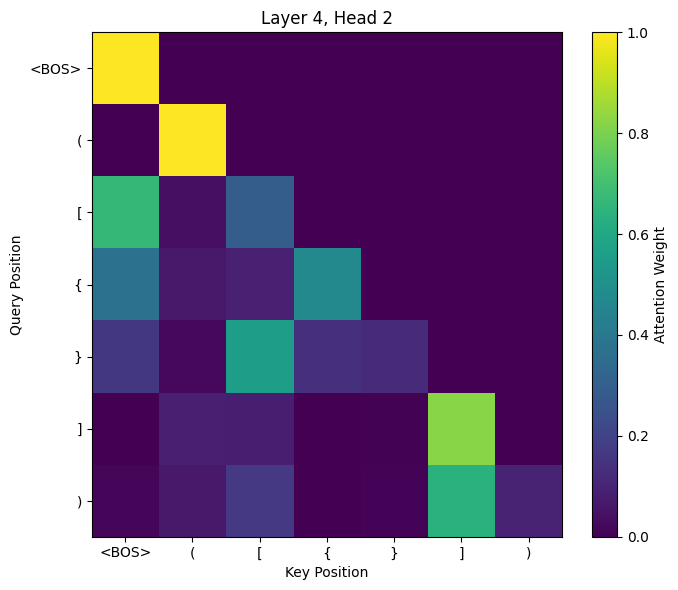

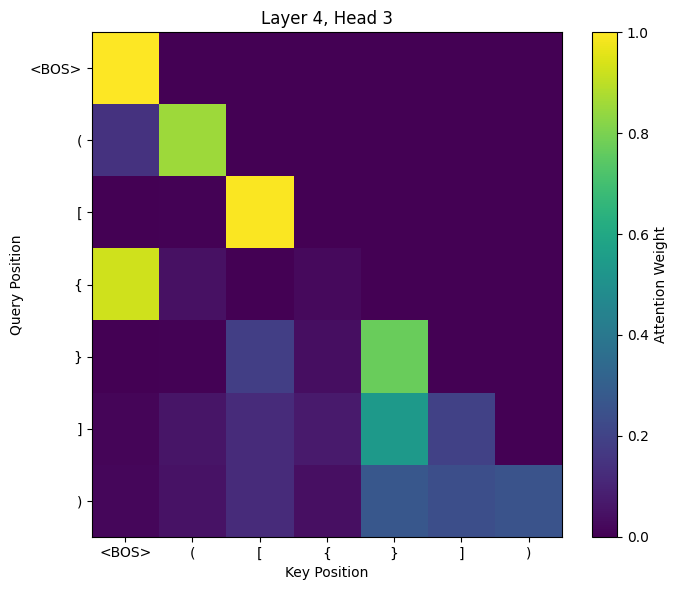

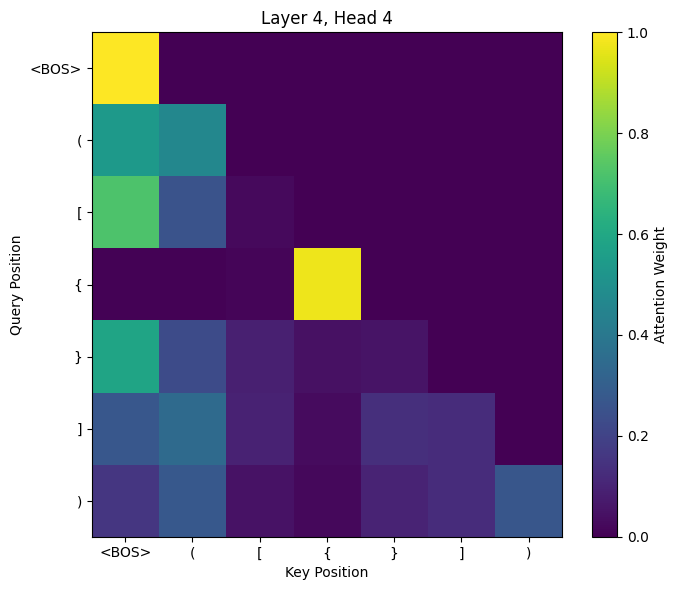


Interpretation reminder:
Attention maps show where a head places weight, not whether that head causally determines the prediction.


In [41]:
# ============================================================
# 15. Interpretability Probe 1 — Attention Maps
# ============================================================

import matplotlib.pyplot as plt

model.eval()

# Hand-picked balanced sequence with nested bracket structure.
probe_tokens = [
    "<BOS>",
    "(",
    "[",
    "{",
    "}",
    "]",
    ")"
]

probe_ids = [
    token_to_id[token]
    for token in probe_tokens
]

probe_tensor = torch.tensor(
    [probe_ids],
    dtype=torch.long,
    device=device
)

with torch.no_grad():
    probe_logits, probe_attentions, probe_residuals = model(
        probe_tensor,
        return_probes=True
    )

print("Probe sequence:")
print(" ".join(probe_tokens))

print("\nNumber of layers captured:",
      len(probe_attentions))

for layer_idx, attention in enumerate(probe_attentions):

    print(
        f"Layer {layer_idx + 1} attention shape:",
        tuple(attention.shape)
    )


# ------------------------------------------------------------
# Plot each head separately for maximum readability
# ------------------------------------------------------------

for layer_idx, attention in enumerate(probe_attentions):

    # Remove batch dimension:
    # (1, heads, seq, seq) -> (heads, seq, seq)
    attention = attention[0].detach().cpu()

    for head_idx in range(attention.shape[0]):

        weights = attention[head_idx].numpy()

        plt.figure(figsize=(7, 6))

        plt.imshow(
            weights,
            aspect="auto",
            interpolation="nearest"
        )

        plt.colorbar(label="Attention Weight")

        plt.xticks(
            range(len(probe_tokens)),
            probe_tokens
        )

        plt.yticks(
            range(len(probe_tokens)),
            probe_tokens
        )

        plt.xlabel("Key Position")
        plt.ylabel("Query Position")

        plt.title(
            f"Layer {layer_idx + 1}, "
            f"Head {head_idx + 1}"
        )

        plt.tight_layout()
        plt.show()


print(
    "\nInterpretation reminder:"
)
print(
    "Attention maps show where a head places weight, "
    "not whether that head causally determines the prediction."
)

## 16. Interpretability Probe 2 – Logit Lens

The logit lens projects intermediate residual-stream representations through the model's final normalization and output head. This provides a layer-by-layer view of which tokens are linearly decodable as processing progresses.

This probe is descriptive rather than causal. A token becoming highly ranked at an intermediate layer does not establish that the layer or any individual attention head caused the final prediction.

In [42]:
# ============================================================
# 16. Layer-by-Layer Logit-Lens Probe
# ============================================================

model.eval()

with torch.no_grad():
    probe_logits, probe_attentions, probe_residuals = model(
        probe_tensor,
        return_probes=True
    )

# Examine the final sequence position.
position = probe_tensor.shape[1] - 1

print("Logit-Lens Probe")
print("=" * 55)
print("Probe sequence:", " ".join(probe_tokens))
print("Position examined:", position)
print("Token at position:", probe_tokens[position])
print()

layer_predictions = []

with torch.no_grad():
    for layer_idx, residual in enumerate(probe_residuals):

        # Apply the model's final normalization and output head
        # to the intermediate residual stream.
        normalized = model.final_ln(residual)

        layer_logits = model.output_head(normalized)

        position_logits = layer_logits[0, position]

        probabilities = torch.softmax(
            position_logits,
            dim=-1
        )

        top_values, top_indices = torch.topk(
            probabilities,
            k=min(5, probabilities.numel())
        )

        top_tokens = [
            id_to_token[int(idx)]
            for idx in top_indices.cpu()
        ]

        layer_predictions.append(
            (top_tokens, top_values.cpu())
        )

        print(f"Layer {layer_idx + 1}")
        print("-" * 30)

        for rank, (token, probability) in enumerate(
            zip(top_tokens, top_values.cpu()),
            start=1
        ):
            print(
                f"Rank {rank}: {token:>5} "
                f"| probability = {probability.item():.4f}"
            )

        print()

print("=" * 55)
print("PASS: layer-by-layer logit-lens probe completed.")

Logit-Lens Probe
Probe sequence: <BOS> ( [ { } ] )
Position examined: 6
Token at position: )

Layer 1
------------------------------
Rank 1:     ] | probability = 0.4277
Rank 2:     { | probability = 0.2243
Rank 3:     [ | probability = 0.0926
Rank 4:     ) | probability = 0.0578
Rank 5:     } | probability = 0.0577

Layer 2
------------------------------
Rank 1:     { | probability = 0.2630
Rank 2:     [ | probability = 0.2184
Rank 3:     ( | probability = 0.1459
Rank 4:     } | probability = 0.1110
Rank 5: <PAD> | probability = 0.1070

Layer 3
------------------------------
Rank 1:     { | probability = 0.1777
Rank 2:     [ | probability = 0.1660
Rank 3:     ) | probability = 0.1503
Rank 4:     ( | probability = 0.1374
Rank 5: <PAD> | probability = 0.1122

Layer 4
------------------------------
Rank 1:     [ | probability = 0.3593
Rank 2:     { | probability = 0.3307
Rank 3:     ( | probability = 0.3090
Rank 4:     ) | probability = 0.0005
Rank 5:     } | probability = 0.0003

PASS: 

## 17. Causal Intervention — Attention-Head Ablation

The attention maps in Section 15 provide descriptive evidence about where individual attention heads place weight, but an attention pattern alone does not establish that a head is causally necessary for the model's predictions.

To test causal importance more directly, this experiment performs single-head ablation. One attention head at a time is zeroed after scaled dot-product attention and before the head outputs are recombined and projected through the output projection \(W_O\).

The trained model is first evaluated without intervention to establish a baseline. Each of the 16 attention heads (4 layers × 4 heads) is then independently ablated while all other model parameters and activations remain unchanged.

For each intervention, the change in cross-entropy loss and next-token accuracy is measured relative to baseline performance. A head whose removal produces a substantial degradation provides stronger evidence of causal importance than a visually distinctive attention map alone.

This experiment remains scoped: ablation can demonstrate that a component contributes to model behavior, but it does not by itself establish the complete algorithm implemented by that component.

In [43]:
# ============================================================
# 17. Causal Intervention — Attention-Head Ablation
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np

model.eval()

# ------------------------------------------------------------
# Experimental settings
# ------------------------------------------------------------

NUM_EVAL_BATCHES = 20
EVAL_BATCH_SIZE = 64
NUM_PAIRS = 8

num_layers = len(model.blocks)
num_heads = model.blocks[0].attention.num_heads


# ------------------------------------------------------------
# Create fixed evaluation batches
#
# Every intervention is tested on exactly the same data so that
# differences are caused by the intervention rather than by
# different randomly generated sequences.
# ------------------------------------------------------------

model_device = next(model.parameters()).device
print("Model device:", model_device)

ablation_eval_batches = []

for _ in range(NUM_EVAL_BATCHES):
    x_batch, y_batch = make_batch(
        batch_size=EVAL_BATCH_SIZE,
        num_pairs=NUM_PAIRS
    )
    # Move evaluation data to the same device as the model.
    x_batch = x_batch.to(model_device)
    y_batch = y_batch.to(model_device)

    ablation_eval_batches.append((x_batch, y_batch))

# Device sanity check
print("Model parameter device:", next(model.parameters()).device)
print("Evaluation x device:", ablation_eval_batches[0][0].device)
print("Evaluation y device:", ablation_eval_batches[0][1].device)

# ------------------------------------------------------------
# Evaluation helper
# ------------------------------------------------------------

def evaluate_intervention(
    model,
    eval_batches,
    ablate_layer=None,
    ablate_head=None
):
    losses = []
    accuracies = []

    with torch.no_grad():

        for x_batch, y_batch in eval_batches:

            logits = model(
                x_batch,
                ablate_layer=ablate_layer,
                ablate_head=ablate_head
            )

            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                y_batch.reshape(-1)
            )

            predictions = logits.argmax(dim=-1)

            accuracy = (
                predictions == y_batch
            ).float().mean()

            losses.append(loss.item())
            accuracies.append(accuracy.item())

    return (
        float(np.mean(losses)),
        float(np.mean(accuracies))
    )


# ------------------------------------------------------------
# Baseline — no ablation
# ------------------------------------------------------------

baseline_loss, baseline_accuracy = evaluate_intervention(
    model,
    ablation_eval_batches
)

print("Causal Head-Ablation Experiment")
print("=" * 64)
print(f"Evaluation batches : {NUM_EVAL_BATCHES}")
print(f"Sequences tested   : {NUM_EVAL_BATCHES * EVAL_BATCH_SIZE}")
print(f"Transformer layers : {num_layers}")
print(f"Heads per layer    : {num_heads}")
print()
print(f"Baseline loss      : {baseline_loss:.4f}")
print(f"Baseline accuracy  : {baseline_accuracy:.4f}")
print()


# ------------------------------------------------------------
# Single-head interventions
# ------------------------------------------------------------

ablation_results = []

for layer_idx in range(num_layers):

    for head_idx in range(num_heads):

        ablated_loss, ablated_accuracy = evaluate_intervention(
            model,
            ablation_eval_batches,
            ablate_layer=layer_idx,
            ablate_head=head_idx
        )

        delta_loss = ablated_loss - baseline_loss

        delta_accuracy = (
            ablated_accuracy - baseline_accuracy
        )

        result = {
            "layer": layer_idx + 1,
            "head": head_idx + 1,
            "loss": ablated_loss,
            "accuracy": ablated_accuracy,
            "delta_loss": delta_loss,
            "delta_accuracy": delta_accuracy
        }

        ablation_results.append(result)

        print(
            f"Layer {layer_idx + 1}, "
            f"Head {head_idx + 1} | "
            f"Loss {ablated_loss:.4f} "
            f"(Δ {delta_loss:+.4f}) | "
            f"Accuracy {ablated_accuracy:.4f} "
            f"(Δ {delta_accuracy:+.4f})"
        )


# ------------------------------------------------------------
# Identify largest behavioral effects
# ------------------------------------------------------------

largest_loss_effect = max(
    ablation_results,
    key=lambda result: result["delta_loss"]
)

largest_accuracy_drop = min(
    ablation_results,
    key=lambda result: result["delta_accuracy"]
)

print("\n" + "=" * 64)

print("Largest increase in loss:")
print(
    f"Layer {largest_loss_effect['layer']}, "
    f"Head {largest_loss_effect['head']} | "
    f"Δ loss = "
    f"{largest_loss_effect['delta_loss']:+.4f}"
)

print("\nLargest decrease in accuracy:")
print(
    f"Layer {largest_accuracy_drop['layer']}, "
    f"Head {largest_accuracy_drop['head']} | "
    f"Δ accuracy = "
    f"{largest_accuracy_drop['delta_accuracy']:+.4f}"
)

print("\nPASS: all 16 single-head ablations completed.")

Model device: mps:0
Model parameter device: mps:0
Evaluation x device: mps:0
Evaluation y device: mps:0
Causal Head-Ablation Experiment
Evaluation batches : 20
Sequences tested   : 1280
Transformer layers : 4
Heads per layer    : 4

Baseline loss      : 0.9573
Baseline accuracy  : 0.5453

Layer 1, Head 1 | Loss 1.0702 (Δ +0.1129) | Accuracy 0.5206 (Δ -0.0247)
Layer 1, Head 2 | Loss 0.9731 (Δ +0.0158) | Accuracy 0.5420 (Δ -0.0032)
Layer 1, Head 3 | Loss 0.9708 (Δ +0.0136) | Accuracy 0.5426 (Δ -0.0027)
Layer 1, Head 4 | Loss 1.0157 (Δ +0.0585) | Accuracy 0.5334 (Δ -0.0118)
Layer 2, Head 1 | Loss 0.9751 (Δ +0.0178) | Accuracy 0.5406 (Δ -0.0046)
Layer 2, Head 2 | Loss 1.0460 (Δ +0.0888) | Accuracy 0.5231 (Δ -0.0222)
Layer 2, Head 3 | Loss 0.9951 (Δ +0.0379) | Accuracy 0.5333 (Δ -0.0119)
Layer 2, Head 4 | Loss 0.9726 (Δ +0.0154) | Accuracy 0.5431 (Δ -0.0021)
Layer 3, Head 1 | Loss 0.9711 (Δ +0.0139) | Accuracy 0.5419 (Δ -0.0034)
Layer 3, Head 2 | Loss 1.0058 (Δ +0.0485) | Accuracy 0.5338 (Δ